Πώς κατανέμονται οι ημερήσιες αποδόσεις της μετοχής της Apple Inc. (AAPL) σε σχέση με τον όγκο συναλλαγών της και σε ποιο βαθμό η μεταβλητότητα των τιμών συνοδεύεται από αυξημένη δραστηριότητα των επενδυτών; Η κατανόηση της σχέσης μεταξύ ημερήσιας απόδοσης και όγκου συναλλαγών είναι κομβικής σημασίας για την αξιολόγηση της ρευστότητας και της αποτελεσματικότητας της αγοράς, καθώς παρέχει ενδείξεις για το αν οι μεγάλες διακυμάνσεις στις τιμές πυροδοτούνται από υψηλό όγκο συναλλαγών.

=== DATA AUDIT ===
Shape: (506, 11)
date             datetime64[ns]
AAPL.Open               float64
AAPL.High               float64
AAPL.Low                float64
close                   float64
volume                    int64
AAPL.Adjusted           float64
dn                      float64
mavg                    float64
up                      float64
direction                object
dtype: object

Missing Values:
 date             0
AAPL.Open        0
AAPL.High        0
AAPL.Low         0
close            0
volume           0
AAPL.Adjusted    0
dn               0
mavg             0
up               0
direction        0
dtype: int64

=== FIRST 3 SIMPLE RETURNS ===
1    0.006962
2   -0.002098
3    0.008174
Name: Simple_Return, dtype: float64


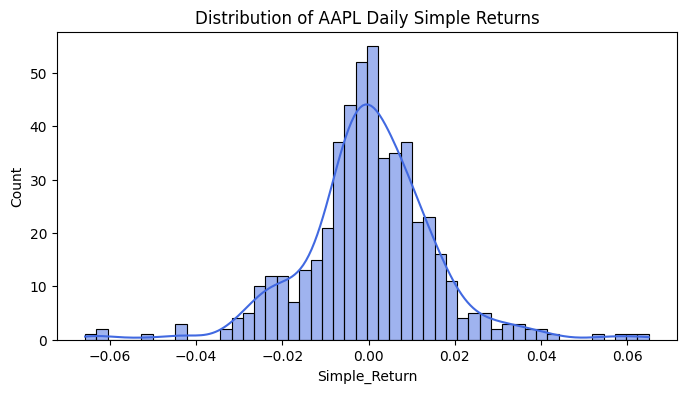

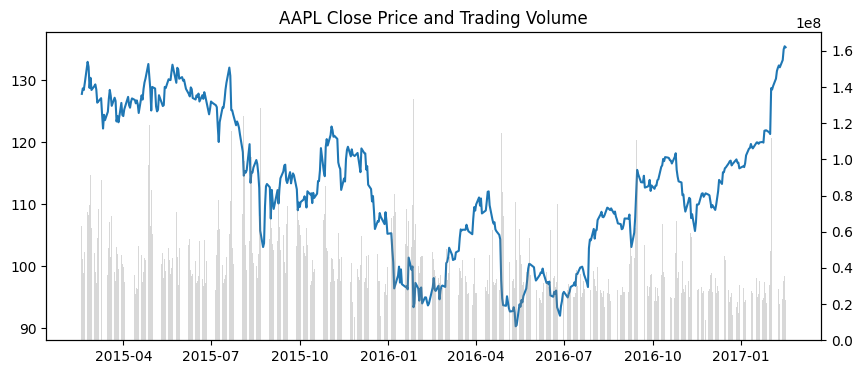

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Φόρτωση δεδομένων από το επίσημο αποθετήριο του μαθήματος (data_dictionary.md)
url = "https://raw.githubusercontent.com/plotly/datasets/master/finance-charts-apple.csv"
df = pd.read_csv(url)

# Μετονομασία στηλών για αναγνωσιμότητα
df = df.rename(columns={'Date': 'date', 'AAPL.Close': 'close', 'AAPL.Volume': 'volume'})
df['date'] = pd.to_datetime(df['date'])

# Data Audit
print("=== DATA AUDIT ===")
print(f"Shape: {df.shape}")
print(df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())

# Υπολογισμός Απλών Αποδόσεων
df['Simple_Return'] = df['close'].pct_change()

# Πρώτες 3 αποδόσεις
print("\n=== FIRST 3 SIMPLE RETURNS ===")
print(df['Simple_Return'].dropna().head(3))

# Διάγραμμα Κατανομής
plt.figure(figsize=(8, 4))
sns.histplot(df['Simple_Return'].dropna(), kde=True, bins=50, color='royalblue')
plt.title("Distribution of AAPL Daily Simple Returns")
plt.show()

# Διάγραμμα Χρονοσειράς & Όγκου
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(df['date'], df['close'], color='tab:blue', label='Close Price')
ax2 = ax1.twinx()
ax2.bar(df['date'], df['volume'], color='tab:gray', alpha=0.3, label='Volume')
plt.title("AAPL Close Price and Trading Volume")
plt.show()

Τα δεδομένα της περιόδου 2015–2017 δείχνουν ότι η κατανομή των ημερήσιων αποδόσεων της Apple παρουσιάζει ισχυρή συγκέντρωση γύρω από το μηδέν με ελαφρώς θετική μέση τιμή, εμφανίζοντας παράλληλα «παχιές ουρές» (fat tails) και ακραίες τιμές (outliers), γεγονός που υποδηλώνει απόκλιση από την κανονική κατανομή. Στο διάγραμμα χρονοσειράς παρατηρείται ότι η τιμή της μετοχής κινήθηκε πτωτικά/σταθεροποιητικά στα τέλη του 2015 και τις αρχές του 2016, πριν ξεκινήσει μια ανοδική τροχιά προς τα τέλη του 2016, ενώ οι εξάρσεις στον όγκο συναλλαγών συμπίπτουν κυρίως με περιόδους έντονης διακύμανσης των τιμών και ανακοινώσεις εταιρικών αποτελεσμάτων.
Τα ιστορικά αυτά στοιχεία τιμών και όγκου δεν επαρκούν για να θεμελιώσουν αιτιώδη σχέση (causality) μεταξύ του όγκου συναλλαγών και της κατεύθυνσης της τιμής, καθώς ένας υψηλός όγκος μπορεί να εκφράζει είτε πίεση πωλήσεων είτε αυξημένη αγοραστική ζήτηση. Επιπλέον, τα στατιστικά ευρήματα αυτής της διετίας (2015–2017) δεν μπορούν να αποδείξουν αν η μετοχή ήταν υποτιμημένη ή υπερτιμημένη χωρίς τη χρήση θεμελιώδους ανάλυσης, ούτε μπορούν να εγγυηθούν τις μελλοντικές αποδόσεις του τίτλου σε μεταγενέστερες περιόδους.

Dataset Citation: Source repository: https://github.com/plotly/datasets   Direct file: https://raw.githubusercontent.com/plotly/datasets/master/finance-charts-apple.csv   Observation unit: One daily Apple market observation

AI Disclosure: Η τεχνητή νοημοσύνη χρησιμοποιήθηκε υποστηρικτικά για τη δομή και τον κώδικα, αλλά κάθε τμήμα κώδικα και ισχυρισμός επαληθεύτηκε σε καθαρή συνεδρία.